# 2 · From two measurements to one score

Each synthesis gives a **size** and a **dispersion**. The optimiser needs **one number per experiment**,
so we must decide what "good" means. This is a chemical decision, not a coding one.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # use the local package without installing it
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nanobo as nb

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [2]:
lab = nb.VirtualLab(seed=1)                 # the virtual lab (invented chemistry + noise)
X = nb.latin_hypercube(6, seed=42)
size, disp = lab.run(X)
df = pd.DataFrame(X, columns=nb.SHORT)
df["size_nm"], df["disp_pct"] = size, disp
df.round(2)

,conc_M,ratio_OA_Fe,temp_C,size_nm,disp_pct
0,0.18,2.71,314.28,13.38,47.65
1,0.15,4.94,293.50,2.99,67.36
2,0.10,1.14,292.48,11.73,36.86
3,0.28,3.42,300.49,6.99,3.97
4,0.23,3.78,310.38,11.06,5.30
5,0.08,1.96,286.24,9.68,11.89


## Score 1 — "100 minus penalties"

$$\text{score} = 100 - 5\,(\text{size}-10)^2 - 15\,\max(0,\ \text{disp}-4)^2$$

Easy to read: 100 is perfect, each gap costs points, and the weights say that 1 % of excess dispersion
costs three times more than 1 nm of size error.

In [3]:
df["penalty_score"] = nb.penalty_score(df.size_nm, df.disp_pct)
df[["size_nm", "disp_pct", "penalty_score"]].round(1)

,size_nm,disp_pct,penalty_score
0,13.4,47.6,-28532.5
1,3.0,67.4,-60356.9
2,11.7,36.9,-16114.0
3,7.0,4.0,54.8
4,11.1,5.3,69.1
5,9.7,11.9,-834.2


**Its weak point: no floor.** A single failed synthesis can score thousands of points below zero.
The Gaussian process then spends its effort describing *how bad* the failures are, instead of where the good recipes are.
The weights also mix units (nm² and %²) in a way that is hard to justify.

## Score 2 — desirabilities and a geometric mean

Each property is mapped to a **desirability between 0 and 1**:

* $d_\text{size} = \exp\big(-((\text{size}-10)/1.5)^2\big)$ — 1 at 10 nm, 0.37 at ±1.5 nm
* $d_\text{disp}$ — 1 for dispersion ≤ 4 %, falling linearly to 0 at 12 %

and the score is their **geometric mean** $\sqrt{d_\text{size}\,d_\text{disp}}$:
bounded between 0 and 1, unit-free, and **one unacceptable property gives zero** — a perfect size cannot compensate a
very broad distribution.

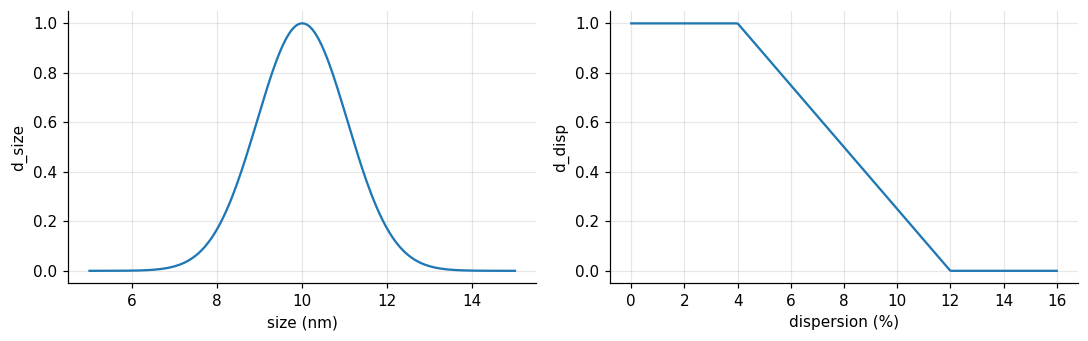

,size_nm,disp_pct,penalty_score,score
0,13.376,47.647,-28532.450,0.000
1,2.991,67.357,-60356.946,0.000
2,11.730,36.862,-16113.971,0.000
3,6.993,3.969,54.778,0.134
4,11.063,5.297,69.110,0.712
5,9.675,11.889,-834.180,0.115


In [4]:
s = np.linspace(5, 15, 300); d = np.linspace(0, 16, 300)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(s, nb.d_size(s)); ax[0].set_xlabel("size (nm)"); ax[0].set_ylabel("d_size")
ax[1].plot(d, nb.d_disp(d)); ax[1].set_xlabel("dispersion (%)"); ax[1].set_ylabel("d_disp")
plt.tight_layout(); plt.show()

df["score"] = nb.desirability_score(df.size_nm, df.disp_pct)
df[["size_nm", "disp_pct", "penalty_score", "score"]].round(3)

In [5]:
# A worked example, by hand
size_ex, disp_ex = 11.0, 6.0
ds, dd = nb.d_size(size_ex), nb.d_disp(disp_ex)
print(f"d_size = {ds:.3f}, d_disp = {dd:.3f}, score = sqrt({ds:.3f} x {dd:.3f}) = {np.sqrt(ds*dd):.3f}")

d_size = 0.641, d_disp = 0.750, score = sqrt(0.641 x 0.750) = 0.693


## Take-aways

* The score encodes **our priorities**; changing it changes what the optimiser looks for.
* Prefer a **bounded** score: one failed synthesis should not dominate the model.
* Weights can still be added to the geometric mean as exponents, e.g. $d_\text{size}^{0.4}\,d_\text{disp}^{0.6}$.
* From now on the tutorial uses `desirability_score`.